# Autoregressive Next-Word Text Generation: SimpleRNN vs Bidirectional RNN vs LSTM vs GRU

**Dataset:** Tiny Shakespeare (word-level) - https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

**Goal:** Train four recurrent models under *identical* experimental conditions to predict the next word, evaluate them
quantitatively (loss, perplexity, accuracy, training time) and qualitatively (coherence, diversity, repetition), and study
the effect of sampling temperature on generated text.

**How to run (Google Colab):** `Runtime -> Change runtime type -> T4 GPU`, then `Runtime -> Run all`.
Training all four models takes about 5.5 minutes in total on a T4 GPU (57-121 s per model).
All outputs (plots, tables, generated text) are saved in `results/`.

**Notebook outline**
1. Setup and configuration
2. Dataset: download and description
3. Preprocessing, vocabulary, input-target sequences
4. Model definitions
5. Training (same conditions for all models)
6. Quantitative evaluation
7. Text generation with temperature
8. Generated samples, text-quality metrics and summary
9. Analysis

## 1. Setup and configuration

In [1]:
import os, re, time, json, random, shutil, urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

# ------------ Experiment configuration: IDENTICAL for all four models ------------
SEED          = 42
SEQ_LEN       = 20      # context window (words) used to predict the next word
VOCAB_SIZE    = 5000    # includes <pad> (id 0) and <unk> (id 1)
EMB_DIM       = 128
UNITS         = 256     # width of the recurrent layer output
DROPOUT       = 0.3
BATCH_SIZE    = 128
EPOCHS        = 15      # maximum; early stopping may end training sooner
LR            = 1e-3
CLIPNORM      = 1.0     # gradient clipping (helps SimpleRNN stability; used for all models)
PATIENCE      = 3       # early-stopping patience on validation loss
DATA_FRACTION = 1.0     # set to e.g. 0.5 for a quick test run on less data

MODEL_KINDS  = ["simplernn", "birnn", "lstm", "gru"]
MODEL_LABELS = {"simplernn": "SimpleRNN", "birnn": "BiRNN", "lstm": "LSTM", "gru": "GRU"}

def set_all_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

set_all_seeds()
for d in ["data", "models", "results"]:
    os.makedirs(d, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPUs      :", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPUs      : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Dataset: download and description

**Tiny Shakespeare** is a ~1 MB plain-text file made by concatenating a selection of Shakespeare's plays
(Karpathy, *The Unreasonable Effectiveness of Recurrent Neural Networks*, `char-rnn` repository).
Text is dialogue-style: a speaker name followed by a colon, then the lines they speak.

Source: https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

In [2]:
DATA_URL  = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
DATA_PATH = "data/tinyshakespeare.txt"

if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

raw_text = open(DATA_PATH, encoding="utf-8").read()
lines = raw_text.split("\n")
non_empty = [l for l in lines if l.strip()]
speaker_lines = [l for l in non_empty if re.fullmatch(r"[A-Za-z' ]+:", l.strip())]

print(f"Characters          : {len(raw_text):,}")
print(f"Lines (non-empty)   : {len(non_empty):,}")
print(f"Speaker-turn headers: {len(speaker_lines):,}  (e.g. {speaker_lines[:3]})")
print("\n--- first 400 characters ---")
print(raw_text[:400])

Characters          : 1,115,394
Lines (non-empty)   : 32,777
Speaker-turn headers: 7,960  (e.g. ['First Citizen:', 'All:', 'First Citizen:'])

--- first 400 characters ---
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it 


## 3. Preprocessing, vocabulary and input-target sequences

Preprocessing steps:
1. Lowercase.
2. Split punctuation `. , ! ? ; :` into separate tokens (so the model can learn sentence structure).
3. Remove other special characters and extra whitespace.
4. Tokenize on whitespace (word-level).
5. Keep the top `VOCAB_SIZE - 2` most frequent words; every other word becomes `<unk>`.

Total tokens (words + punctuation): 250,145
Unique tokens                      : 12,636
Type-token ratio                   : 0.0505
Words appearing only once          : 5,704 (45.1% of vocabulary)

Vocabulary size used: 5,000  | token coverage: 96.17%  | <unk> rate: 3.83%


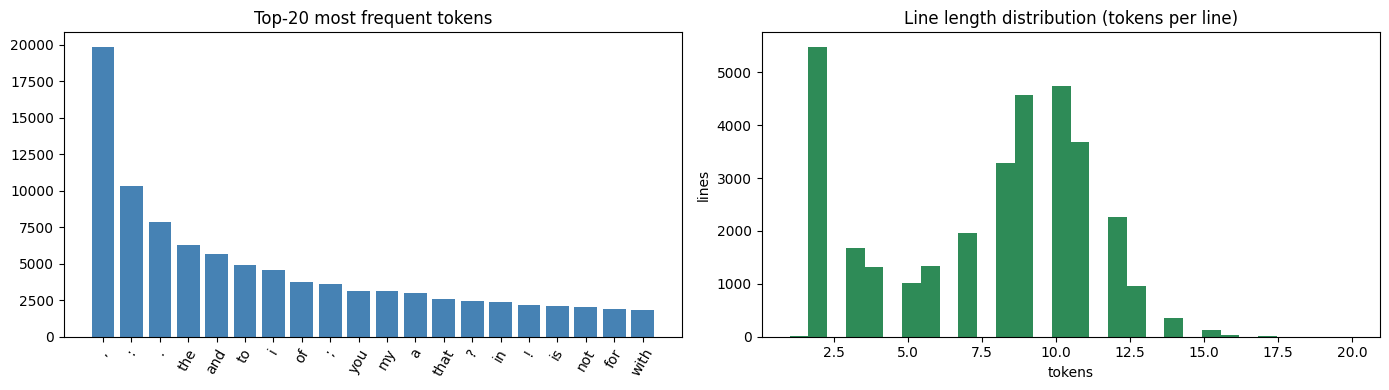

Mean line length: 7.6 tokens


In [3]:
def tokenize(s):
    s = s.lower()
    s = re.sub(r"([.,!?;:])", r" \1 ", s)
    s = re.sub(r"[^a-z.,!?;:'\s]", " ", s)
    return [t for t in s.split() if t != "'"]

tokens = tokenize(raw_text)

counts = Counter(tokens)
total_tokens = len(tokens)
unique_words = len(counts)
hapax = sum(1 for c in counts.values() if c == 1)

print(f"Total tokens (words + punctuation): {total_tokens:,}")
print(f"Unique tokens                      : {unique_words:,}")
print(f"Type-token ratio                   : {unique_words / total_tokens:.4f}")
print(f"Words appearing only once          : {hapax:,} ({hapax / unique_words:.1%} of vocabulary)")

# ---- vocabulary ----
vocab = ["<pad>", "<unk>"] + [w for w, _ in counts.most_common(VOCAB_SIZE - 2)]
w2i = {w: i for i, w in enumerate(vocab)}
i2w = {i: w for w, i in w2i.items()}
coverage = sum(counts[w] for w in vocab[2:]) / total_tokens
print(f"\nVocabulary size used: {len(vocab):,}  | token coverage: {coverage:.2%}  | <unk> rate: {1 - coverage:.2%}")

# ---- dataset characteristic plots ----
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
top = counts.most_common(20)
ax[0].bar([w for w, _ in top], [c for _, c in top], color="steelblue")
ax[0].set_title("Top-20 most frequent tokens"); ax[0].tick_params(axis="x", rotation=60)
line_lens = [len(tokenize(l)) for l in non_empty]
ax[1].hist(line_lens, bins=30, color="seagreen")
ax[1].set_title("Line length distribution (tokens per line)"); ax[1].set_xlabel("tokens"); ax[1].set_ylabel("lines")
plt.tight_layout(); plt.savefig("results/dataset_characteristics.png", dpi=150); plt.show()
print(f"Mean line length: {np.mean(line_lens):.1f} tokens")

In [4]:
# ---- integer-encode the corpus ----
ids = np.array([w2i.get(w, 1) for w in tokens], dtype=np.int32)
if DATA_FRACTION < 1.0:
    ids = ids[: int(len(ids) * DATA_FRACTION)]

# ---- sliding window: input = SEQ_LEN words, target = the next word ----
n_seq = len(ids) - SEQ_LEN
idx = np.arange(SEQ_LEN)[None, :] + np.arange(n_seq)[:, None]
X = ids[idx]            # (n_seq, SEQ_LEN)
y = ids[SEQ_LEN:]       # (n_seq,)
print("X:", X.shape, " y:", y.shape)

# ---- chronological 80/10/10 split with a SEQ_LEN gap so windows never overlap across splits ----
tr_end = int(0.8 * n_seq)
va_end = int(0.9 * n_seq)
X_train, y_train = X[:tr_end],                  y[:tr_end]
X_val,   y_val   = X[tr_end + SEQ_LEN: va_end], y[tr_end + SEQ_LEN: va_end]
X_test,  y_test  = X[va_end + SEQ_LEN:],        y[va_end + SEQ_LEN:]
print(f"train: {len(X_train):,} | val: {len(X_val):,} | test: {len(X_test):,}")

# ---- example of an input-target pair ----
print("\nExample input :", " ".join(i2w[i] for i in X_train[100]))
print("Example target:", i2w[int(y_train[100])])

# words used for n-gram statistics of the TRAINING portion only (used later for text-quality metrics)
train_words = [i2w[int(i)] for i in ids[: tr_end + SEQ_LEN]]

X: (250125, 20)  y: (250125,)
train: 200,100 | val: 24,992 | test: 24,993

Example input : second citizen : one word , good citizens . first citizen : we are <unk> poor citizens , the patricians
Example target: good


## 4. Model definitions

All four models share the same pipeline: `Embedding -> recurrent layer -> Dropout -> Dense(softmax over vocabulary)`.
Only the recurrent layer changes:

| Model | Recurrent layer | Notes |
|---|---|---|
| SimpleRNN | `SimpleRNN(256)` | no gates; prone to vanishing gradients |
| BiRNN | `Bidirectional(SimpleRNN(128))` | reads the *seed window of past words* forwards and backwards; output width = 2 x 128 = 256 (same as the others). It never sees future words, so it is valid for next-word prediction |
| LSTM | `LSTM(256)` | input/forget/output gates + cell state |
| GRU | `GRU(256)` | update/reset gates, fewer parameters than LSTM |

In [5]:
def build_model(kind):
    inp = layers.Input(shape=(SEQ_LEN,), dtype="int32")
    x = layers.Embedding(VOCAB_SIZE, EMB_DIM)(inp)
    if kind == "simplernn":
        x = layers.SimpleRNN(UNITS)(x)
    elif kind == "birnn":
        x = layers.Bidirectional(layers.SimpleRNN(UNITS // 2))(x)
    elif kind == "lstm":
        x = layers.LSTM(UNITS)(x)
    elif kind == "gru":
        x = layers.GRU(UNITS)(x)
    else:
        raise ValueError(kind)
    x = layers.Dropout(DROPOUT)(x)
    out = layers.Dense(VOCAB_SIZE, activation="softmax")(x)
    model = models.Model(inp, out, name=kind)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LR, clipnorm=CLIPNORM),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy", tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5")],
    )
    return model

for k in MODEL_KINDS:
    m = build_model(k)
    print(f"{MODEL_LABELS[k]:10s} parameters: {m.count_params():,}")

SimpleRNN  parameters: 2,023,560
BiRNN      parameters: 1,990,792
LSTM       parameters: 2,319,240
GRU        parameters: 2,221,448


## 5. Training (comparable conditions)

Same data, split, seed, embedding size, recurrent width, dropout, optimizer, learning rate, gradient clipping, batch size,
maximum epochs and early-stopping rule for every model. Training time is recorded both as total time and as
**seconds per epoch** (since early stopping can make models run for different numbers of epochs).

In [6]:
class EpochTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.times = []
    def on_epoch_begin(self, epoch, logs=None):
        self._t = time.time()
    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.time() - self._t)

trained_models, histories, rows = {}, {}, {}

for kind in MODEL_KINDS:
    print("=" * 70); print("Training:", MODEL_LABELS[kind]); print("=" * 70)
    set_all_seeds()
    model = build_model(kind)
    timer = EpochTimer()
    early = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)

    t0 = time.time()
    hist = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                     epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=[early, timer], verbose=2)
    total_time = time.time() - t0

    h = hist.history
    best_ep = int(np.argmin(h["val_loss"]))
    val_loss,  val_acc,  val_top5  = model.evaluate(X_val,  y_val,  batch_size=512, verbose=0)
    test_loss, test_acc, test_top5 = model.evaluate(X_test, y_test, batch_size=512, verbose=0)

    rows[MODEL_LABELS[kind]] = {
        "parameters": model.count_params(),
        "epochs_run": len(h["loss"]),
        "best_epoch": best_ep + 1,
        "train_time_s": round(total_time, 1),
        "sec_per_epoch": round(float(np.mean(timer.times)), 1),
        "train_loss": h["loss"][best_ep],
        "val_loss": val_loss,
        "test_loss": test_loss,
        "val_perplexity": float(np.exp(val_loss)),
        "test_perplexity": float(np.exp(test_loss)),
        "test_top1_acc_%": 100 * test_acc,
        "test_top5_acc_%": 100 * test_top5,
    }
    trained_models[kind] = model
    histories[kind] = {k: [float(v) for v in vals] for k, vals in h.items()}
    model.save(f"models/{kind}.keras")

with open("results/training_histories.json", "w") as f:
    json.dump(histories, f, indent=2)

Training: SimpleRNN
Epoch 1/15
1564/1564 - 22s - 14ms/step - accuracy: 0.1282 - loss: 5.5740 - top5: 0.2784 - val_accuracy: 0.1509 - val_loss: 5.2942 - val_top5: 0.3323
Epoch 2/15
1564/1564 - 11s - 7ms/step - accuracy: 0.1591 - loss: 5.0293 - top5: 0.3349 - val_accuracy: 0.1574 - val_loss: 5.2127 - val_top5: 0.3502
Epoch 3/15
1564/1564 - 8s - 5ms/step - accuracy: 0.1675 - loss: 4.8092 - top5: 0.3525 - val_accuracy: 0.1579 - val_loss: 5.2232 - val_top5: 0.3534
Epoch 4/15
1564/1564 - 8s - 5ms/step - accuracy: 0.1740 - loss: 4.6391 - top5: 0.3659 - val_accuracy: 0.1593 - val_loss: 5.2474 - val_top5: 0.3567
Epoch 5/15
1564/1564 - 8s - 5ms/step - accuracy: 0.1799 - loss: 4.4965 - top5: 0.3757 - val_accuracy: 0.1582 - val_loss: 5.2905 - val_top5: 0.3565
Training: BiRNN
Epoch 1/15
1564/1564 - 20s - 13ms/step - accuracy: 0.1301 - loss: 5.5394 - top5: 0.2822 - val_accuracy: 0.1495 - val_loss: 5.2772 - val_top5: 0.3361
Epoch 2/15
1564/1564 - 10s - 7ms/step - accuracy: 0.1609 - loss: 5.0210 - top

## 6. Quantitative evaluation

* **Loss** = cross-entropy of the next-word prediction.
* **Perplexity** = `exp(loss)`; lower is better (roughly, "how many words the model is effectively choosing between").
* **Top-1 / Top-5 accuracy** = how often the true next word is the top prediction / among the 5 most probable.
  Next-word accuracy is naturally low for any model because many continuations are plausible.
* **Training time** = total seconds and seconds per epoch.

In [7]:
results_df = pd.DataFrame(rows).T
results_df.index.name = "model"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
results_df.to_csv("results/metrics.csv")
display(results_df)

,parameters,epochs_run,best_epoch,train_time_s,sec_per_epoch,train_loss,val_loss,test_loss,val_perplexity,test_perplexity,test_top1_acc_%,test_top5_acc_%
model,,,,,,,,,,,,
SimpleRNN,"2,023,560.000",5.000,2.000,57.400,11.500,5.029,5.213,5.591,183.586,267.888,15.916,34.786
BiRNN,"1,990,792.000",5.000,2.000,62.100,12.400,5.021,5.195,5.580,180.415,265.144,14.488,35.038
LSTM,"2,319,240.000",8.000,5.000,120.900,15.100,4.626,5.133,5.640,169.533,281.569,15.284,35.502
GRU,"2,221,448.000",6.000,3.000,84.300,14.000,4.714,5.044,5.422,155.030,226.232,15.180,37.519


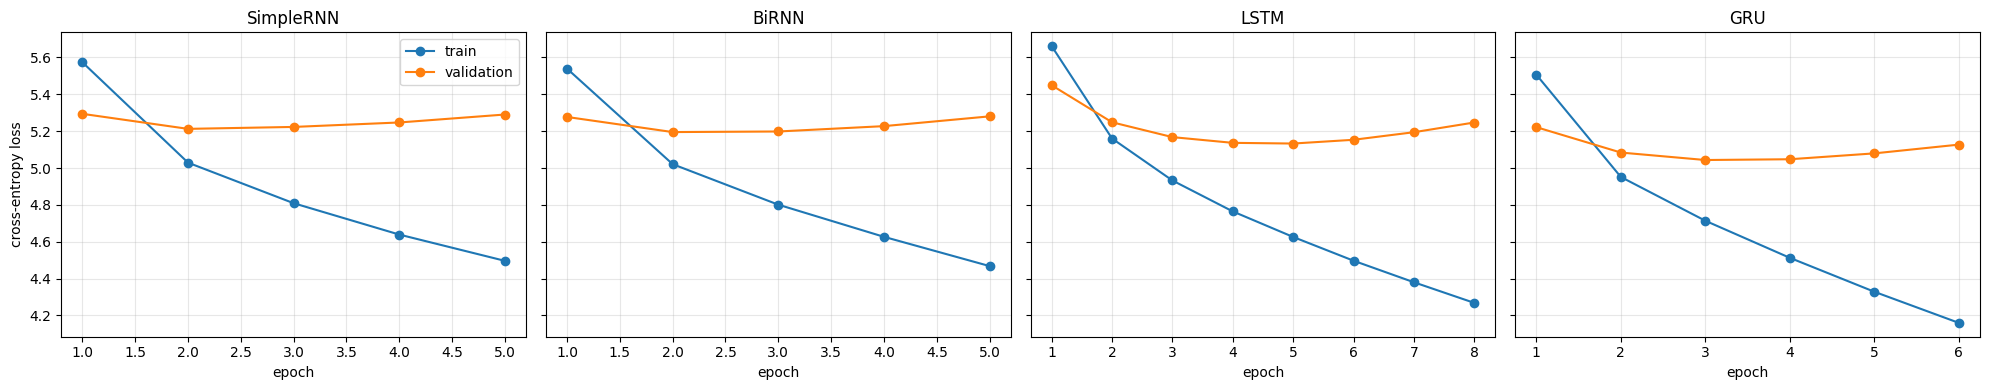

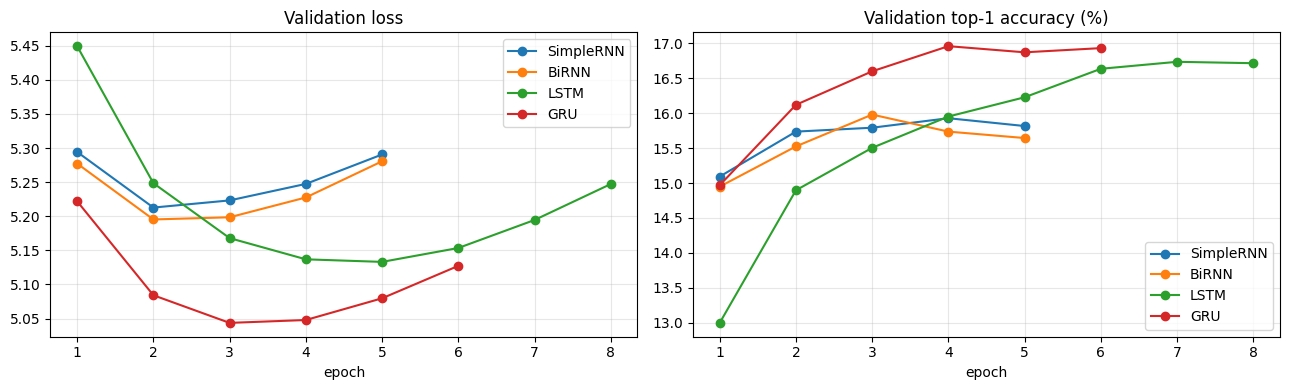

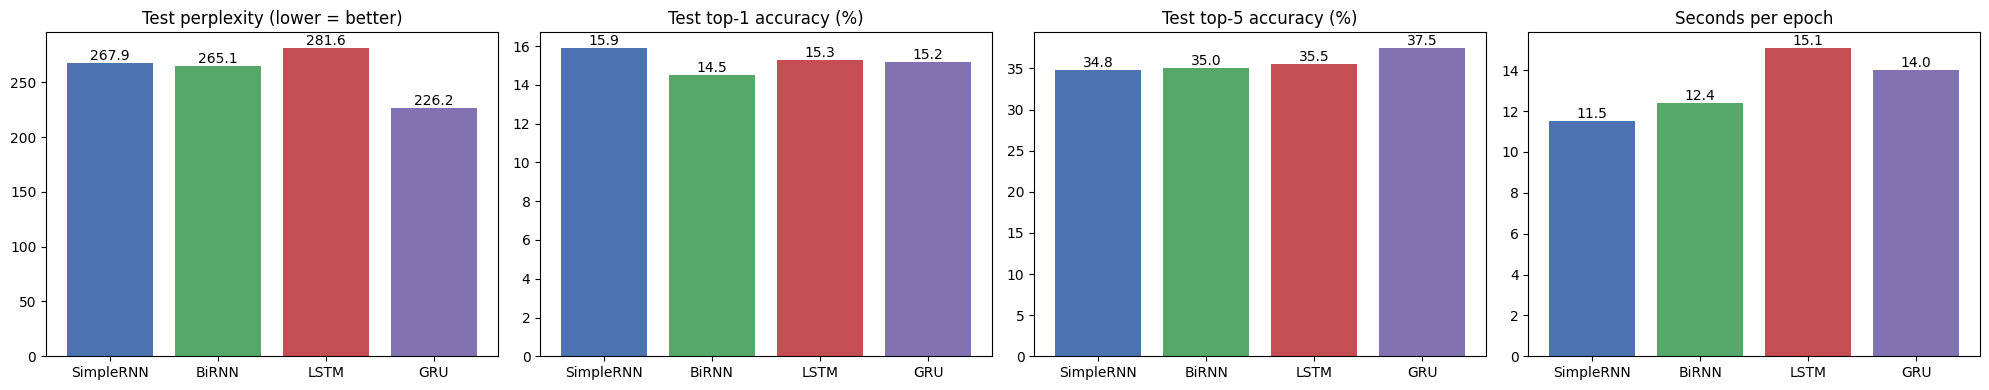

In [8]:
# ---- training / validation loss curves ----
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, kind in zip(axes, MODEL_KINDS):
    h = histories[kind]; ep = range(1, len(h["loss"]) + 1)
    ax.plot(ep, h["loss"], marker="o", label="train")
    ax.plot(ep, h["val_loss"], marker="o", label="validation")
    ax.set_title(MODEL_LABELS[kind]); ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
axes[0].set_ylabel("cross-entropy loss"); axes[0].legend()
plt.tight_layout(); plt.savefig("results/loss_curves.png", dpi=150); plt.show()

# ---- validation accuracy and loss, all models on one plot ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for kind in MODEL_KINDS:
    h = histories[kind]; ep = range(1, len(h["loss"]) + 1)
    axes[0].plot(ep, h["val_loss"], marker="o", label=MODEL_LABELS[kind])
    axes[1].plot(ep, [100 * a for a in h["val_accuracy"]], marker="o", label=MODEL_LABELS[kind])
axes[0].set_title("Validation loss"); axes[1].set_title("Validation top-1 accuracy (%)")
for a in axes: a.set_xlabel("epoch"); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.savefig("results/validation_comparison.png", dpi=150); plt.show()

# ---- bar charts: perplexity, accuracy, time per epoch ----
labels = list(results_df.index)
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col, title in zip(axes,
        ["test_perplexity", "test_top1_acc_%", "test_top5_acc_%", "sec_per_epoch"],
        ["Test perplexity (lower = better)", "Test top-1 accuracy (%)", "Test top-5 accuracy (%)", "Seconds per epoch"]):
    vals = results_df[col].astype(float).values
    bars = ax.bar(labels, vals, color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"])
    ax.set_title(title)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.1f}", ha="center", va="bottom")
plt.tight_layout(); plt.savefig("results/metric_bars.png", dpi=150); plt.show()

## 7. Text generation with temperature

Generation is **autoregressive**: predict a probability distribution for the next word, sample one word,
append it to the context window, and repeat.

Temperature `T` rescales the distribution before sampling: `p_i ~ exp(log(p_i) / T)`.
Low `T` -> sharper distribution (safe, predictable); high `T` -> flatter distribution (more random).

The same three seed phrases and the same temperatures are used for every model. Because the seeds are shorter than the
`SEQ_LEN`-word window, the beginning of the training corpus is used as neutral left context (`<pad>` is never seen in training, so it is avoided).
`<pad>` and `<unk>` are blocked from being generated.

In [9]:
PREFIX = tokens[:SEQ_LEN]   # neutral dialogue-style left context (first words of the corpus)

SEEDS = [
    "to be or not to be , that is the",
    "my lord , i do beseech you to",
    "i will not leave thee , for the king",
]
TEMPERATURES = [0.5, 1.0, 1.5]

def make_window(seed_tokens):
    full = PREFIX + seed_tokens
    return [w2i.get(w, 1) for w in full[-SEQ_LEN:]]

def generate_batch(model, seed_text, n_words, temperature, n_runs, rng):
    # Generates n_runs independent continuations in parallel (Gumbel-max sampling == sampling from softmax(logits/T)).
    seed_tokens = tokenize(seed_text)
    win = np.tile(np.array(make_window(seed_tokens), dtype=np.int32), (n_runs, 1))
    generated = [[] for _ in range(n_runs)]
    for _ in range(n_words):
        probs = np.asarray(model(win, training=False)).astype("float64")
        logits = np.log(probs + 1e-9) / temperature
        logits[:, :2] = -1e9                                   # never generate <pad> or <unk>
        gumbel = -np.log(-np.log(rng.random(logits.shape) + 1e-12) + 1e-12)
        nxt = np.argmax(logits + gumbel, axis=1)
        for r in range(n_runs):
            generated[r].append(i2w[int(nxt[r])])
        win = np.concatenate([win[:, 1:], nxt[:, None].astype(np.int32)], axis=1)
    return seed_tokens, generated

def detok(words):
    s = " ".join(words)
    return re.sub(r" ([.,!?;:])", r"\1", s)

## 8. Generated samples, text-quality metrics and summary

The next cell generates text from the trained models (reloading them from `models/` if the session was restarted). It produces:

* **Qualitative samples:** 36 texts = 4 models x 3 seeds x 3 temperatures (0.5, 1.0, 1.5), saved to `results/generated_samples.txt`.
* **Quantitative text-quality metrics:** 5 continuations of 100 words for each model x temperature x seed (180 texts), averaged.
* **Temperature plots and a combined summary table.**

The same seed phrases and the same random stream are used for every model, and the random stream differs between seeds and temperatures.

| Metric | Meaning | Reads as |
|---|---|---|
| `distinct_1`, `distinct_2` | unique unigrams / bigrams divided by total | **diversity** (higher = more varied) |
| `rep_3` | share of trigram occurrences that repeat an earlier trigram in the same text | **repetition** (higher = more looping) |
| `bigram_valid` | share of generated bigrams that occur in the training text | **local fluency / coherence proxy** |
| `trigram_valid` | share of generated trigrams that occur in the training text | **copying vs novelty** (very high = copying, very low = incoherent) |


################################################################################
TEMPERATURE = 0.5 | SEED = "to be or not to be , that is the"
################################################################################
[SimpleRNN] to be or not to be, that is the || people, as he had made you, to morrow, to the earl of the rest, that i may not you, to have a man. third servingman: why, i am a while i have
[BiRNN    ] to be or not to be, that is the || people, as he is to you, as i have been to bear a little. what, i have not you, i have not to rome, she is not not: for you, i am
[LSTM     ] to be or not to be, that is the || people, as he had been you to see and yet, i will be not. what, i am not that our general is? leontes: if she were so, i am a while, and
[GRU      ] to be or not to be, that is the || provost. polixenes: that's the good fellow. brutus: away, and the people. third citizen: that's not that our general. third servingman: ay, and i am: for you are, and

##########

distinct_1  distinct_2  rep_3  bigram_valid  \
temperature model                                                    
0.500       SimpleRNN       0.481       0.825  0.048         0.954   
            BiRNN           0.487       0.849  0.037         0.967   
            LSTM            0.502       0.869  0.030         0.965   
            GRU             0.491       0.837  0.051         0.974   
1.000       SimpleRNN       0.715       0.981  0.000         0.677   
            BiRNN           0.699       0.987  0.000         0.695   
            LSTM            0.715       0.989  0.000         0.714   
            GRU             0.717       0.993  0.000         0.700   
1.500       SimpleRNN       0.878       0.999  0.000         0.279   
            BiRNN           0.887       1.000  0.000         0.262   
            LSTM            0.861       1.000  0.000         0.356   
            GRU             0.877       1.000  0.000         0.305   

                       trigram_valid  
temperature model                     
0.500       SimpleRNN          0.656  
            BiRNN              0.678  
            LSTM               0.675  
            GRU                0.724  
1.000       SimpleRNN          0.214  
            BiRNN              0.206  
            LSTM               0.238  
            GRU                0.222  
1.500       SimpleRNN          0.020  
            BiRNN              0.018  
            LSTM               0.039  
            GRU                0.030

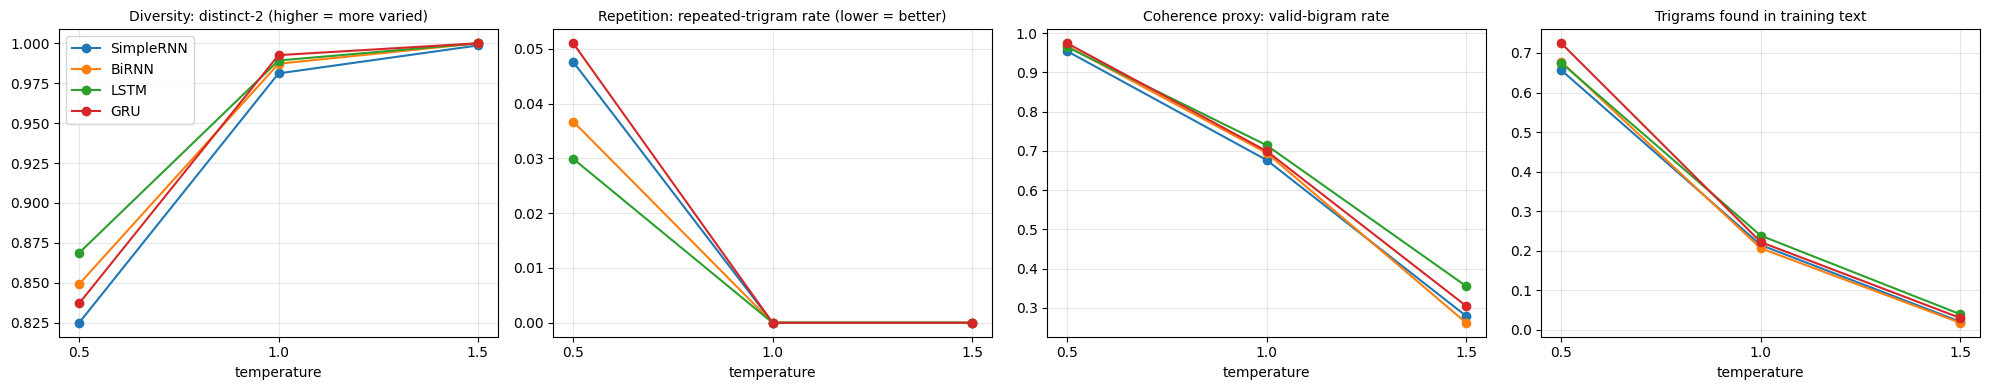

,parameters,sec_per_epoch,test_perplexity,test_top1_acc_%,test_top5_acc_%,distinct_2@T=1.0,rep_3@T=1.0,bigram_valid@T=1.0
model,,,,,,,,
SimpleRNN,"2,023,560.000",11.500,267.888,15.916,34.786,0.981,0.000,0.677
BiRNN,"1,990,792.000",12.400,265.144,14.488,35.038,0.987,0.000,0.695
LSTM,"2,319,240.000",15.100,281.569,15.284,35.502,0.989,0.000,0.714
GRU,"2,221,448.000",14.000,226.232,15.180,37.519,0.993,0.000,0.700


Least repetition @T=1.0        : SimpleRNN
Highest valid-bigram rate @T=1.0: LSTM
Files in results/: ['dataset_characteristics.png', 'generated_samples.txt', 'generation_metrics_raw.csv', 'generation_metrics_summary.csv', 'loss_curves.png', 'metric_bars.png', 'metrics.csv', 'summary.csv', 'temperature_analysis.png', 'training_histories.json', 'validation_comparison.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
# ===== UPDATED generation section: different random streams per seed/temperature, same across models =====
import os, re, shutil
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf

# --- reload models / metrics if the session was restarted ---
if "trained_models" not in globals():
    trained_models = {k: tf.keras.models.load_model(f"models/{k}.keras") for k in MODEL_KINDS}
if "results_df" not in globals():
    results_df = pd.read_csv("results/metrics.csv", index_col="model")

def run_rng(si, temp):
    # same stream for every model (fair), different for each seed and temperature
    return np.random.default_rng(SEED + 100 * si + int(round(temp * 10)))

# ---------------- 8.1 Qualitative samples (4 models x 3 seeds x 3 temperatures) ----------------
sample_lines = []
for temp in TEMPERATURES:
    for si, seed in enumerate(SEEDS):
        sample_lines.append("\n" + "#" * 80)
        sample_lines.append(f'TEMPERATURE = {temp} | SEED = "{seed}"')
        sample_lines.append("#" * 80)
        for kind in MODEL_KINDS:
            rng = run_rng(si, temp)
            seed_toks, gen = generate_batch(trained_models[kind], seed, n_words=40,
                                            temperature=temp, n_runs=1, rng=rng)
            sample_lines.append(f"[{MODEL_LABELS[kind]:9s}] {detok(seed_toks)} || {detok(gen[0])}")

samples_text = "\n".join(sample_lines)
print(samples_text)
with open("results/generated_samples.txt", "w", encoding="utf-8") as f:
    f.write(samples_text)

# ---------------- 8.2 Quantitative text-quality metrics ----------------
train_bigrams  = set(zip(train_words[:-1], train_words[1:]))
train_trigrams = set(zip(train_words[:-2], train_words[1:-1], train_words[2:]))

def ngrams(toks, n):
    return list(zip(*[toks[i:] for i in range(n)]))

def distinct_n(toks, n):
    g = ngrams(toks, n)
    return len(set(g)) / max(len(g), 1)

def repetition_rate(toks, n=3):
    g = ngrams(toks, n)
    return (len(g) - len(set(g))) / max(len(g), 1)

def valid_rate(toks, n, train_set):
    g = ngrams(toks, n)
    return sum(1 for x in g if x in train_set) / max(len(g), 1)

N_METRIC_WORDS, N_RUNS = 100, 5
metric_rows = []
for kind in MODEL_KINDS:
    for temp in TEMPERATURES:
        for si, seed in enumerate(SEEDS):
            rng = run_rng(si, temp)
            _, gens = generate_batch(trained_models[kind], seed, N_METRIC_WORDS, temp, N_RUNS, rng)
            for r, g in enumerate(gens):
                metric_rows.append({
                    "model": MODEL_LABELS[kind], "temperature": temp, "seed": seed, "run": r,
                    "distinct_1": distinct_n(g, 1), "distinct_2": distinct_n(g, 2),
                    "rep_3": repetition_rate(g, 3),
                    "bigram_valid": valid_rate(g, 2, train_bigrams),
                    "trigram_valid": valid_rate(g, 3, train_trigrams),
                })

gen_metrics = pd.DataFrame(metric_rows)
gen_metrics.to_csv("results/generation_metrics_raw.csv", index=False)

METRIC_COLS = ["distinct_1", "distinct_2", "rep_3", "bigram_valid", "trigram_valid"]
gen_summary = gen_metrics.groupby(["temperature", "model"])[METRIC_COLS].mean()
gen_summary = gen_summary.reindex([MODEL_LABELS[k] for k in MODEL_KINDS], level="model")
gen_summary.to_csv("results/generation_metrics_summary.csv")
display(gen_summary)

# ---------------- temperature plots ----------------
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
titles = {"distinct_2": "Diversity: distinct-2 (higher = more varied)",
          "rep_3": "Repetition: repeated-trigram rate (lower = better)",
          "bigram_valid": "Coherence proxy: valid-bigram rate",
          "trigram_valid": "Trigrams found in training text"}
for ax, col in zip(axes, titles):
    for kind in MODEL_KINDS:
        name = MODEL_LABELS[kind]
        vals = [gen_summary.loc[(t, name), col] for t in TEMPERATURES]
        ax.plot(TEMPERATURES, vals, marker="o", label=name)
    ax.set_title(titles[col], fontsize=10); ax.set_xlabel("temperature")
    ax.set_xticks(TEMPERATURES); ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout(); plt.savefig("results/temperature_analysis.png", dpi=150); plt.show()

# ---------------- 9. Summary table ----------------
mid_T = TEMPERATURES[len(TEMPERATURES) // 2]
summary = results_df[["parameters", "sec_per_epoch", "test_perplexity", "test_top1_acc_%", "test_top5_acc_%"]].copy()
for col in ["distinct_2", "rep_3", "bigram_valid"]:
    summary[f"{col}@T={mid_T}"] = [gen_summary.loc[(mid_T, m), col] for m in summary.index]
summary.to_csv("results/summary.csv")
display(summary)

print(f"Least repetition @T={mid_T}        :", gen_summary.xs(mid_T, level="temperature")["rep_3"].idxmin())
print(f"Highest valid-bigram rate @T={mid_T}:", gen_summary.xs(mid_T, level="temperature")["bigram_valid"].idxmax())

# ---------------- bundle results ----------------
shutil.make_archive("results_bundle", "zip", "results")
print("Files in results/:", sorted(os.listdir("results")))
try:
    from google.colab import files
    files.download("results_bundle.zip")
except Exception:
    pass

> **Note:** at T = 1.0 the repeated-trigram rate (`rep_3`) is 0.000 for all four models, so "Least repetition @T=1.0" above is a four-way tie. The code prints the first model in the list.

## 9. Analysis

### 9.1 Model comparison and evaluation

**Predictive quality.** GRU is the clear leader. Its validation perplexity (155.0) is about 9% lower than the next best model (LSTM, 169.5), and its test perplexity (226.2) is about 15% lower than the next best (BiRNN, 265.1). It also has the highest top-5 accuracy (37.5% against 34.8-35.5%). SimpleRNN, BiRNN and LSTM are close on test perplexity (265-282), and their order changes between validation and test (LSTM is second on validation but last on test), so with a single training run their relative order should not be over-interpreted. Top-1 accuracy barely separates the models (14.5-15.9%), because many continuations are plausible for any context. Perplexity and top-5 accuracy are more informative.

**Training behaviour.** Every model overfits quickly: validation loss is lowest at epoch 2 (SimpleRNN, BiRNN), 3 (GRU) and 5 (LSTM), and then rises while training loss keeps falling. The gap between training and validation loss at the best epoch is largest for LSTM (0.51) and GRU (0.33), and smallest for SimpleRNN and BiRNN (0.17-0.18). The gated models learn more from the data and reach lower validation loss, but also memorise faster. A small 250k-token corpus with a 5,000-word output layer makes overfitting unavoidable without stronger regularisation.

**Cost.** SimpleRNN is fastest (11.5 s/epoch), BiRNN next (12.4), then GRU (14.0) and LSTM (15.1). In total training time GRU (84 s) was much cheaper than LSTM (121 s) because it reached its best validation loss earlier. GRU therefore gives the best accuracy per unit of compute among the gated models.

**Bidirectional layer.** The bidirectional SimpleRNN performed within noise of the plain SimpleRNN (test perplexity 265.1 against 267.9, top-1 accuracy lower). Reading the 20-word context backwards gives no clear benefit for next-word prediction here.

**Test versus validation.** Test perplexity is higher than validation perplexity for every model (for example 226 against 155 for GRU). The split is chronological, so the test set is the last 10% of the corpus, which is probably different plays with different names and vocabulary. This is the most likely cause, though it was not tested directly.

**Generated text.** At moderate temperatures all four models reproduce the format of the plays (speaker labels such as `menenius:` and `coriolanus:`, short grammatical phrases like `i am a man`, `good sir`) but not global meaning: sentences wander and characters from different plays appear together (for example `polixenes` and `brutus` in the same passage). The seed influences only the first few words. Even so, there are signs of contextual consistency: after the seed `my lord, i do beseech you to`, both LSTM and GRU at T = 1.0 continue with `the crown. king richard ii: valiant uncle`, a topically linked royal-court context. Character names from the Coriolanus opening (used as neutral left context) appear very often, so that context probably biases the generation slightly.

### 9.2 Sampling-temperature analysis

**T = 0.5 (conservative).** Text is the most locally coherent (valid-bigram rate 0.95-0.97, and 0.65-0.72 of trigrams are copied from the training text) but the least diverse (distinct-2 0.82-0.87) and the only setting with noticeable repetition (repeated-trigram rate 0.03-0.05). It falls into frequent patterns such as `i am a man`, `i would not`, `i have not` and repeated speaker tags, and it reuses phrases from the training data.

**T = 1.0 (balanced).** Repetition disappears (0.000 for all models), diversity is high (distinct-2 0.98-0.99), and about 0.68-0.71 of bigrams are still valid training bigrams. Text is varied and keeps Shakespearean vocabulary, but grammar and sense are frequently broken (`how we hath so so now`). This is the best compromise between diversity and coherence. The differences between models at T = 1.0 are small, comparable to the run-to-run standard error (about 0.01-0.016).

**T = 1.5 (random).** Diversity saturates (distinct-2 about 1.0) but coherence collapses: only 0.26-0.36 of bigrams and 0.02-0.04 of trigrams occur in the training text, and the output is a list of loosely related, often rare words (`keys i shine, deeper more mould wont for some dislike`). Repetition is zero because the distribution is almost flat.

**Overall effect.** Raising the temperature trades coherence for diversity monotonically. Repetition is a low-temperature problem only, while incoherence is a high-temperature problem, so a middle value around T = 1.0 is the most useful. Models differ in how they respond to temperature:
- At low T, GRU is the most coherent (valid-bigram 0.974, trigram-in-train 0.724) but also the most repetitive (0.051) and the one that copies most from the training set. LSTM is the most diverse and least repetitive (distinct-2 0.869, repetition 0.030).
- At T = 1.0 the models are close; GRU has the highest diversity (0.993) and LSTM the highest valid-bigram rate (0.714).
- At T = 1.5, LSTM stays the most coherent (valid-bigram 0.356, against 0.262-0.305 for the others), so it degrades most gracefully at high temperature.

### 9.3 Conclusion: best-performing model

**GRU is the best model for autoregressive generation on this dataset.** It has the lowest validation and test perplexity (155.0 and 226.2), the highest top-5 accuracy (37.5%), and the best local coherence at low temperature, and it reaches its best validation loss in fewer epochs than the LSTM, at about 30% less total training time. At T = 1.0 its generations are as good as any other model's and it has the highest diversity. LSTM is the runner-up: it is the most diverse and least repetitive at T = 0.5 and stays the most coherent at high temperature, but it has the worst test perplexity, the largest overfitting gap and the longest training time. SimpleRNN and BiRNN are the cheapest but have higher perplexity, and the bidirectional layer gave no benefit for next-word prediction.

**Limitations.** Each model was trained once (seed 42), so the small differences among SimpleRNN, BiRNN and LSTM are not conclusive. Only GRU's perplexity advantage is large. The corpus is small (250k tokens), all models overfit after 2-5 epochs, and the vocabulary is capped at 5,000 words (3.8% `<unk>`). The text metrics (valid-bigram rate and so on) are proxies for coherence, not human judgement, and are based on 15 texts per model and temperature. The chronological test split probably contains different plays from the training set.